## Recreating sampling scheme from [Barry et al. (2021)](https://www.nature.com/articles/s41467-021-22573-7) 
"Higher gametocyte production and mosquito infectivity in chronic compared to incident Plasmodium falciparum infections"

Study was conducted between June 2015 and December 2017 in Balonghin, Burkina Faso.  Enrollment was of incident and chronic cohorts of 5-to-10-year-old children.  Incident cohort was given presumptive treatment, confirmed PCR negative, weekly PCR screening, then intensive screening following first PCR positive.  Chronic cohort had same intensive screening following two successive monthly screenings with PCR positive and asymptomatic.  Intensive screening includes blood draws at day 0-7, 14, 21, 28, 35 with further details in their Figure 1 and Methods section.

Some related papers that may inform better parameterization than the somewhat arbitrary demo below:
- https://doi.org/10.7554/eLife.32625.001
- https://www.medrxiv.org/content/10.1101/2025.09.04.25335091v1.full.pdf
- https://doi.org/10.1016/j.crpvbd.2025.100300
- https://doi.org/10.1371/journal.pone.0050036

Overall motivation is a closer inspection of within-host model performance in relation to an out-of-sample dataset compared to past formal calibration.

In [1]:
from seasonal_challenge import monthly_eir_challenge, plot_timeseries, plot_heatmap, ComplexTreatment

### Seasonal infectious challenge

We will re-use some of the same patterns in infectious_reservoir.ipynb to more deeply interrogate trajectories of semi-immune children sampled from incident and chronic infections.

To develop a bit of an intuition for the types of patterns for longitudinal carriage + symptomatic treatment of infections look, you can re-run the following cell multiple times while varying some of the key parameters: monthly EIR numbers, overall scale factor, and treatment probability.

Much of what follows in constructing a specific sample frame for incident and chronic cohorts of 5-to-10-year-olds depends on the specifics of how these trajectories look.

58.5 Annual EIR
70% Treatment of new fever episodes


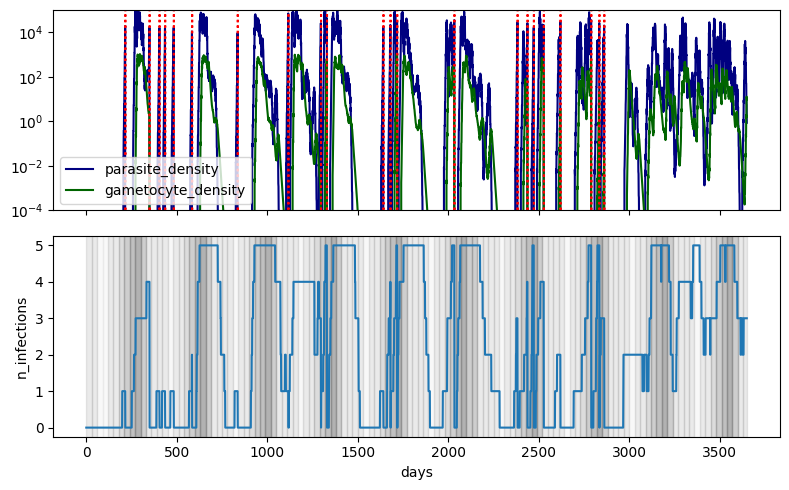

In [46]:
rafin_marke_monthly_eirs = [1, 1, 0.5, 1, 1, 2, 3.875, 7.75, 15.0, 3.875, 1, 1]

scale_factor = 1.5
monthly_eirs = [scale_factor*x for x in rafin_marke_monthly_eirs]
print("%0.1f Annual EIR" % sum(monthly_eirs))

prob_treat = 0.7
print("%d%% Treatment of new fever episodes" % (100*prob_treat))
complex_treatment = ComplexTreatment(prob_treat=prob_treat)

df = monthly_eir_challenge(
    duration=365*10,
    monthly_eirs=monthly_eirs,
    callback=complex_treatment)

plot_timeseries(df, monthly_eirs)

### Sampling of incident cohort

Roughly matching the definition of the incident cohort.  Exact timing of enrollment can be modified with the treatment_day variable below. Glossed over some detail of screening for PCR- at point of presumptive treatment.  That would be relevant to contextualize the fraction of those screened who were enrolled, and would also bias the enrolled population in heterogeneous exposure scenarios.

In [3]:
import numpy as np
from seasonal_challenge import initialize_intrahost

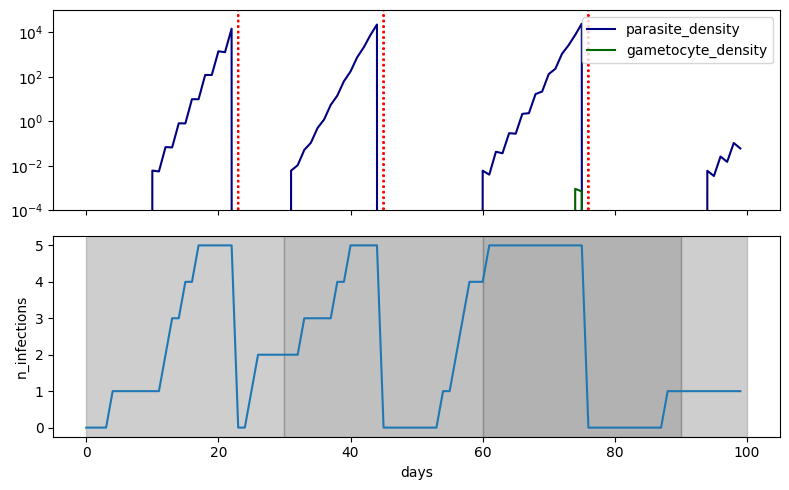

In [47]:
def enroll_incident_cohort(day_of_year):
    age_years = np.random.randint(5, 10)
#     print("%d years old" % age_years)

    ic = initialize_intrahost(
            duration=365*age_years + day_of_year,
            monthly_eirs=monthly_eirs,
            callback=complex_treatment)

    ic.treat()

    df = monthly_eir_challenge(
            duration=100,
            monthly_eirs=monthly_eirs,
            start_day=day_of_year,
            callback=complex_treatment,
            ic=ic)
    
    return df

treatment_day = 200
df = enroll_incident_cohort(day_of_year=treatment_day)
plot_timeseries(df, monthly_eirs, start_day=treatment_day)

### Reproducing something like Supplemental Figure 3A
Here is where we do the post-presumptive-treatment weekly monitoring for first PCR+ and plot intensive daily-then-weekly sampling from that time point forward until either treatment or day-35.

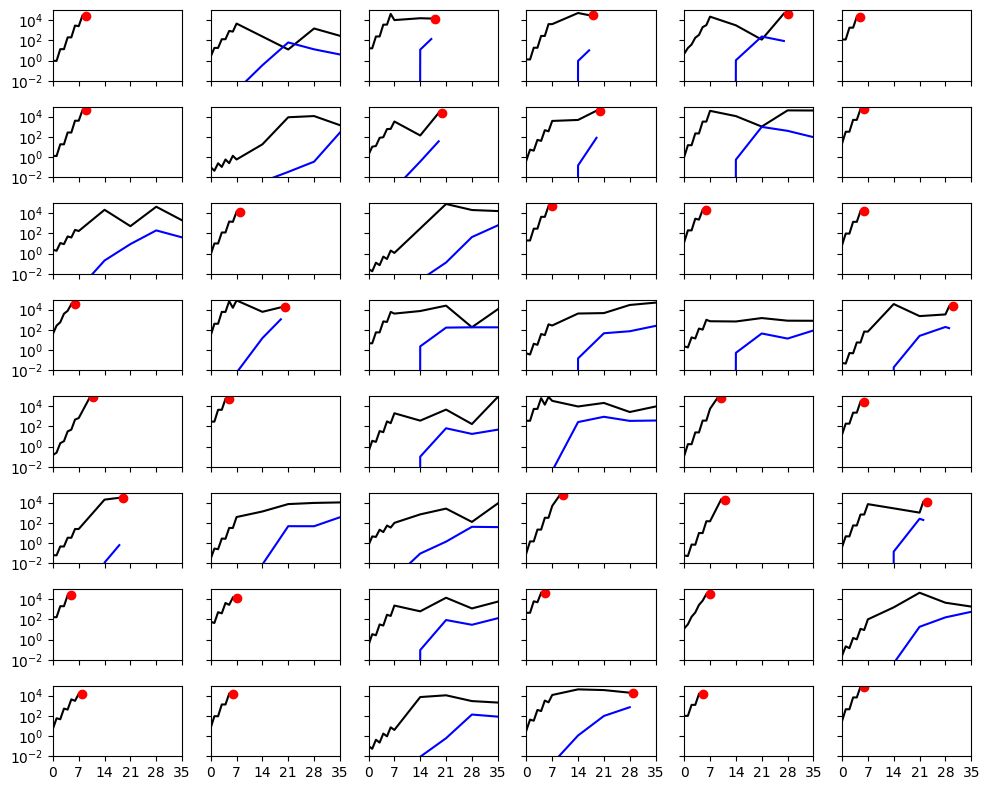

In [103]:
import matplotlib.pyplot as plt

days = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28, 35]

fig, axs = plt.subplots(8, 6, sharex=True, sharey=True, figsize=(10, 8))

def incident_eligible_window(df):
    for detected in range(0, len(df), 7):
        if df.parasite_density.iloc[detected] > 0.01:
            break
#     print("First PCR positive at t=%d" % detected)
    treated = None
    for end in range(detected, len(df)):
        if df.treatments.iloc[end]:
            treated = end
#             print("Treated at t=%d" % treated)
            break
    return detected, treated

def plot_panel(df, detected, treated, ax):

    sample_days = [d for d in days if treated is None or detected+d < treated]
    if treated is not None and treated-detected <= 35:
        sample_days += [treated-detected-1]
    
    ax.plot(sample_days, [df.parasite_density.iloc[detected+d] for d in sample_days], color='black')
    ax.plot(sample_days, [df.gametocyte_density.iloc[detected+d] for d in sample_days], color='blue')
    if treated is not None and treated-detected <= 35:
        ax.plot(treated-detected, df.parasite_density.iloc[treated-1], color='red', marker='o')
    ax.set(
        yscale="log",
        ylim=(1e-2, 1e5),
        yticks=(0.01, 1, 100, 10000),
        xlim=(0, 35),
        xticks=list(range(0, 42, 7)))
    
times_to_detection = []
for ax in axs.flatten():
    while True:
        df = enroll_incident_cohort(day_of_year=200)
        detected, treated = incident_eligible_window(df)
        if detected < 56:
            break
    times_to_detection.append(detected)
    plot_panel(df, detected, treated, ax)
    
fig.set_tight_layout(True)

Distribution of time from treatment until first PCR+ detection, which can be related to Supplemental Figure 1 A + B.

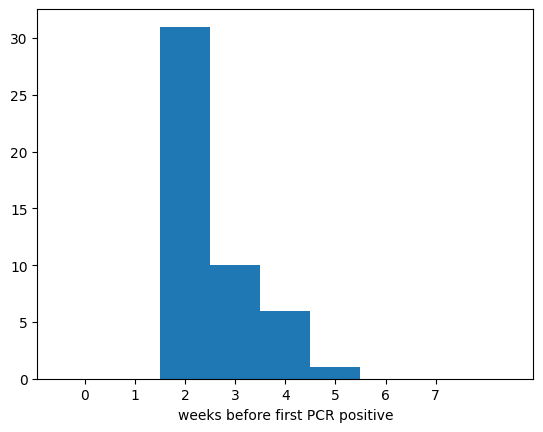

In [104]:
plt.hist([t/7 for t in times_to_detection], bins=np.arange(-0.5, 9.5))
plt.gca().set(xticks=range(8), xlabel="weeks before first PCR positive");

### Sampling of chronic cohort 
This is where we initialize the chronic infection cohort, although the specific criteria for enrollment for follow-up handled in later block of code.  We can re-run this block to get some intuition for the types of trajectories that would pass the filtering criteria, i.e. consecutive monthly PCR+ without intervening disease or current fever.  Changing the season of enrollment for chronic infection going into the peak season can be modified by changing enroll_day below.

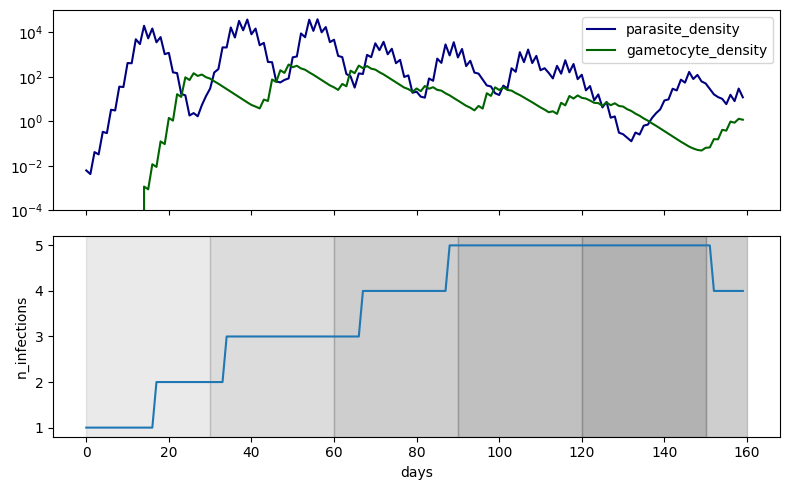

In [105]:
def enroll_chronic_cohort(day_of_year):
    age_years = np.random.randint(5, 10)
#     print("%d years old" % age_years)

    ic = initialize_intrahost(
            duration=365*age_years + day_of_year,
            monthly_eirs=monthly_eirs,
            callback=complex_treatment)
        
    df = monthly_eir_challenge(
            duration=160,
            monthly_eirs=monthly_eirs,
            start_day=day_of_year,
            callback=complex_treatment,
            ic=ic)
    
    return df

enroll_day = 150
df = enroll_chronic_cohort(day_of_year=enroll_day)
plot_timeseries(df, monthly_eirs, start_day=enroll_day)

And below is the logic for consecutive PCR+ detections without treatment during that interval.  It's an approximation of the exact enrollment criteria in the trial, but should serve our purposes.

In [108]:
def chronic_eligible_window(df):
        
    consecutive_positive_count = 0
    for detected in range(0, len(df), 30):
        if df.parasite_density.iloc[detected] > 0.01:
            consecutive_positive_count += 1
        else:
            consecutive_positive_count = 0
        if consecutive_positive_count >= 2:
            break
#     print("Second consecutive PCR positive at t=%d" % detected)
    
    if detected > 120:
        return None, None
    
    treatments_before_chronic = df.treatments.iloc[detected-30:detected].sum()
#     print("Treatment episodes in month before second PCR+ = %d" % treatments_before_chronic)
    if treatments_before_chronic:
        return None, None
    
    treated = None
    for end in range(detected, len(df)):
        if df.treatments.iloc[end]:
            treated = end
#             print("Treated at t=%d" % treated)
            break
    return detected, treated

# df = enroll_chronic_cohort(day_of_year=enroll_day)
# detected, treated = chronic_eligible_window(df)
# print(detected, treated)

### Reproducing something like Supplemental Figure 3B

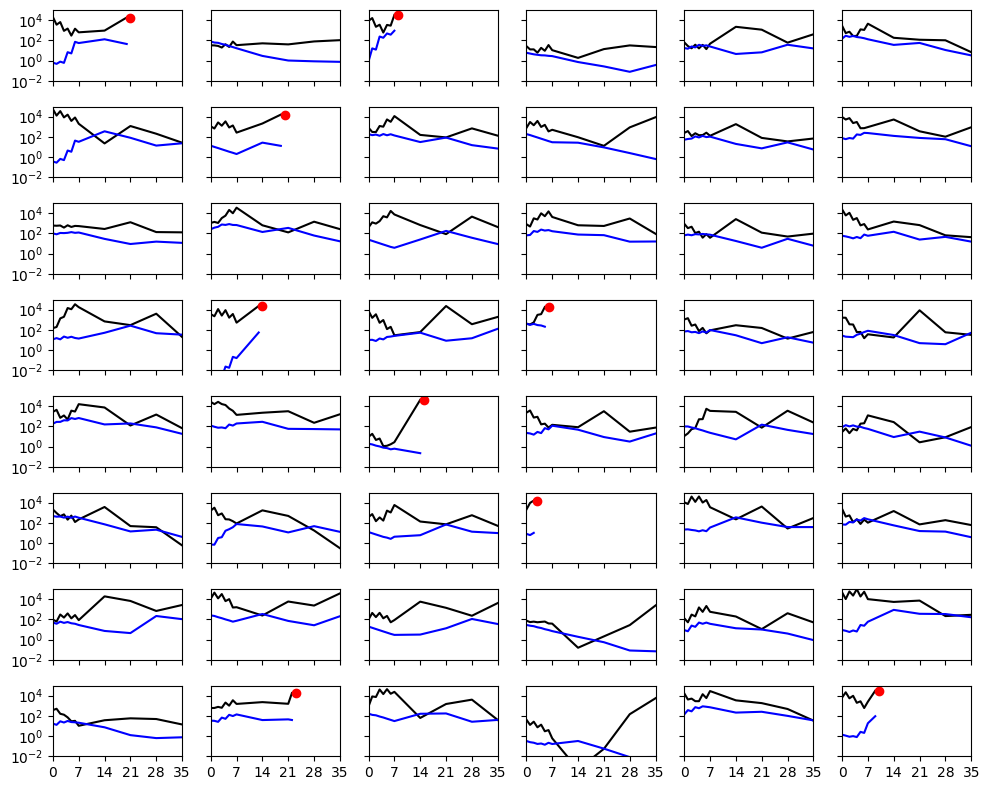

In [109]:
fig, axs = plt.subplots(8, 6, sharex=True, sharey=True, figsize=(10, 8))

times_to_detection = []
for ax in axs.flatten():
    while True:
        df = enroll_chronic_cohort(day_of_year=200)
        detected, treated = chronic_eligible_window(df)
        if detected is not None:
            break
    times_to_detection.append(detected)
    plot_panel(df, detected, treated, ax)
    
fig.set_tight_layout(True)


The above is in the similar style as Supplemental Fig 3B while the plot below can be related to the individual trajectories of enrolled chronic participants in Supplemental Fig 1 C + D.

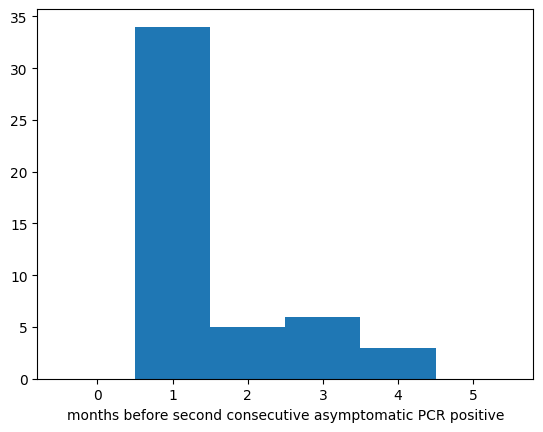

In [114]:
plt.hist([t/30 for t in times_to_detection], bins=np.arange(-0.5, 6.5))
plt.gca().set(xticks=range(6), xlabel="months before second consecutive asymptomatic PCR positive");